In [4]:
from google.colab import drive
drive.mount('/content/drive')
import os
os.chdir('/content/drive/MyDrive/arthritis_trust')
print(os.listdir('.'))

Mounted at /content/drive
['index.xls', 'data_256.npz', 'runs', 'runs.zip']


In [5]:
import os
print("Working folder:", os.getcwd())
print("Files here:", os.listdir("."))
print("_ARR defined:", "_ARR" in globals(), "| _ARR is None:", globals().get("_ARR") is None)

Working folder: /content/drive/MyDrive/arthritis_trust
Files here: ['index.xls', 'data_256.npz', 'runs', 'runs.zip']
_ARR defined: False | _ARR is None: True


In [3]:
!pip install -q xlrd

In [4]:
!pip install -q segmentation-models-pytorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 5.3 MB/s eta 0:00:00


# Uncertainty-Aware Segmentation in Musculoskeletal Ultrasound
## A pipeline study in preparation for synovitis segmentation in arthritis ultrasound

**Author:** Bhagyaprasad Vastrad
**Date:** October 2026
**Notebook 2 of 2:** U-Net baseline

---

## What this notebook does

I train a U-Net on the subject-level splits from notebook 1 and measure per-image Dice on test subjects the model has never seen. This baseline is the starting point for my uncertainty analysis (deep ensembles, Monte Carlo dropout, test-time augmentation, calibration and reliability metrics), which I will add in the next notebook.

I run three experiments:
- **A. Main baseline.** Train on all muscles and conditions.
- **B. Muscle shift.** Train on BB and GM only, then read the TA rows of the test table.
- **C. Disease shift.** Train on healthy muscle only, then read the Pathological rows.

B and C are shifts in the data. They are not scanner or centre shifts, because all images come from one scanner at one centre.

I always run the smoke test first. It trains for one epoch on a tiny subset, only to confirm that everything runs.

## Notes to myself
- The split is fixed in `index.csv`. Changing `seed` only changes the weight initialisation, data order and augmentation, so models trained with different seeds on the same configuration can later form a deep ensemble.
- Dice is computed at 256 x 256 resolution with a threshold of 0.5.

## 1. Setup (Colab only)



In [5]:
# I only need this on Colab. After it finishes I do not restart the runtime.
!pip install -q segmentation-models-pytorch

In [6]:
import json, os, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import segmentation_models_pytorch as smp
from PIL import Image
from torch.utils.data import DataLoader, Dataset

INDEX = "index.xls"      # updated from index.csv to index.xls
OUT_DIR = "runs"         # I save models and results here

# I read images from data_256.npz when it exists (the Colab case).
# Otherwise I fall back to the PNG folders under DATA_ROOT (my own PC).
DATA_ROOT = r"D:\0001_Kings_AI_Project\medical_imaging_ai\data\Polito-Radboud-DeepLearningUS"
NPZ_PATH, NPZ_SIZE = "data_256.npz", 256

_ARR = None
if os.path.exists(NPZ_PATH):
    _z = np.load(NPZ_PATH)
    _ARR = {"imgs": _z["imgs"], "msks": _z["msks"]}
    print("Using compact arrays from", NPZ_PATH, _ARR["imgs"].shape)
else:
    print("No", NPZ_PATH, "found: images will be read from DATA_ROOT")

# I want to see that the GPU is really on
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Using compact arrays from data_256.npz (8169, 256, 256)
Device: cuda


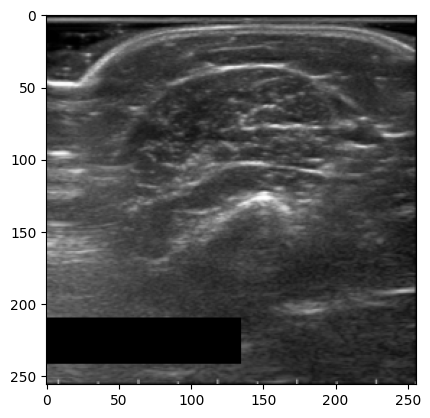

In [7]:
import matplotlib.pyplot as plt
assert "_ARR" in globals() and _ARR is not None, "Run the setup cell that loads data_256.npz first"

# I black out the burned-in text label (bottom left) so the model cannot read the muscle name
_ARR["imgs"][:, 210:242, :135] = 0
plt.imshow(_ARR["imgs"][0], cmap="gray"); plt.show()   # I check that the label is gone and the muscle is untouched

## 2. Dataset class

Each image is turned into a one-channel tensor scaled to [-1, 1]. During training I apply two light augmentations: a random horizontal flip and a small random change of brightness and contrast. I keep the augmentation mild because I do not want to hide the effect of acquisition differences that I study later.

In [8]:
_CACHE = {}   # resized images are kept here so repeated runs do not reload from disk

class USData(Dataset):
    def __init__(self, df, size, train):
        self.size, self.train = size, train
        rows = df.index.to_numpy()                # row numbers in index.csv
        self.meta = df.reset_index(drop=True)     # I keep the metadata for the results table
        self.imgs, self.msks = [], []

        if _ARR is not None and size == NPZ_SIZE:
            # fast path: take the images straight from the compact arrays
            for i in rows:
                self.imgs.append(_ARR["imgs"][i])
                self.msks.append(_ARR["msks"][i])
        else:
            # slow path: read and resize PNG files from DATA_ROOT
            for r in self.meta.itertuples():
                key = (r.muscle, r.condition, r.fname, size)
                if key not in _CACHE:
                    base = os.path.join(DATA_ROOT, r.muscle, r.condition)
                    im = Image.open(os.path.join(base, "Images", r.fname)).convert("L").resize((size, size), Image.BILINEAR)
                    mk = Image.open(os.path.join(base, "Masks", r.fname)).convert("L").resize((size, size), Image.NEAREST)
                    _CACHE[key] = (np.array(im, dtype=np.uint8), (np.array(mk) > 127).astype(np.uint8))
                a, b = _CACHE[key]
                self.imgs.append(a)
                self.msks.append(b)

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, i):
        x = torch.from_numpy(self.imgs[i]).float().div(255).unsqueeze(0)
        y = torch.from_numpy(self.msks[i]).float().unsqueeze(0)
        if self.train:
            if torch.rand(1) < 0.5:                       # random horizontal flip
                x, y = x.flip(-1), y.flip(-1)
            gain = 1 + (torch.rand(1) - 0.5) * 0.2        # brightness gain 0.9 to 1.1
            bias = (torch.rand(1) - 0.5) * 0.1            # intensity shift -0.05 to 0.05
            x = (x * gain + bias).clamp(0, 1)
        return (x - 0.5) / 0.5, y

## 3. Dice score and evaluation

I measure segmentation quality with the Dice score for every image separately, because my later analysis compares per-image uncertainty with per-image error. If both the true mask and the prediction are empty I set the Dice to 1, which is the convention I will document in my methodology.

In [9]:
def dice_per_image(logits, y, eps=1e-6):
    """Per-image Dice at threshold 0.5. If both masks are empty the Dice is 1."""
    p = (torch.sigmoid(logits) > 0.5).float()
    inter = (p * y).sum((1, 2, 3))
    den = p.sum((1, 2, 3)) + y.sum((1, 2, 3))
    return torch.where(den == 0, torch.ones_like(den), 2 * inter / den.clamp(min=eps))


@torch.no_grad()
def evaluate(model, loader):
    """Returns one Dice value per image, in the same order as the dataset."""
    model.eval()
    out = []
    for x, y in loader:
        logits = model(x.to(device))
        out.append(dice_per_image(logits, y.to(device)).cpu())
    return torch.cat(out).numpy()

## 4. Training function

I wrap training in one function so I can run different experiments, and later different seeds for an ensemble, with a single line each.

- **Model:** U-Net with a ResNet34 encoder and ImageNet weights, one input channel.
- **Loss:** binary cross-entropy plus Dice loss.
- **Model selection:** I keep the weights with the best validation Dice and stop early if it does not improve for `patience` epochs.
- **Testing:** the best model is evaluated once on the test subjects, and I save the per-image Dice so I can analyse it later.
- `subsample` is only for quick tests.

In [10]:
def run_experiment(name, train_muscles=("BB", "GM", "TA"), train_condition="all", seed=0,
                   epochs=30, patience=6, batch_size=16, img_size=256, lr=3e-4,
                   encoder="resnet34", encoder_weights="imagenet", subsample=None):
    torch.manual_seed(seed)
    np.random.seed(seed)

    # Try reading as CSV first (since index.xls is actually formatted as a CSV text file)
    try:
        df = pd.read_csv(INDEX, dtype={"subject": str})
    except Exception:
        df = pd.read_excel(INDEX, dtype={"subject": str})

    def pick(split):
        # training and validation use only the muscles and condition I choose
        d = df[(df.split == split) & (df.muscle.isin(train_muscles))]
        if train_condition != "all":
            d = d[d.condition == train_condition]
        return d

    # the test set always contains every muscle and condition, so I can read off any shift
    train_df, val_df, test_df = pick("train"), pick("val"), df[df.split == "test"]
    if subsample:   # small random subset of each split, for quick tests only
        cap = lambda d: d.sample(n=min(subsample, len(d)), random_state=0)
        train_df, val_df, test_df = cap(train_df), cap(val_df), cap(test_df)
    print(f"Train {len(train_df)}  Val {len(val_df)}  Test {len(test_df)} images")

    t0 = time.time()
    train_ds = USData(train_df, img_size, train=True)
    val_ds = USData(val_df, img_size, train=False)
    test_ds = USData(test_df, img_size, train=False)
    print(f"Loaded in {time.time() - t0:.0f}s")

    mk = lambda ds, shuffle: DataLoader(ds, batch_size=batch_size, shuffle=shuffle,
                                        num_workers=0, pin_memory=(device == "cuda"))
    train_dl, val_dl, test_dl = mk(train_ds, True), mk(val_ds, False), mk(test_ds, False)

    weights = None if str(encoder_weights).lower() == "none" else encoder_weights
    model = smp.Unet(encoder, encoder_weights=weights, in_channels=1, classes=1).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    bce, dice_loss = nn.BCEWithLogitsLoss(), smp.losses.DiceLoss("binary")

    run_dir = os.path.join(OUT_DIR, name)
    os.makedirs(run_dir, exist_ok=True)
    best, bad = -1.0, 0

    for ep in range(1, epochs + 1):
        model.train()
        tot = 0.0
        for x, y in train_dl:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = bce(out, y) + dice_loss(out, y)
            opt.zero_grad()
            loss.backward()
            opt.step()
            tot += loss.item() * x.size(0)

        val_dice = float(evaluate(model, val_dl).mean())
        print(f"epoch {ep:02d}  train loss {tot / len(train_ds):.4f}  val Dice {val_dice:.4f}")

        # I keep only the weights with the best validation Dice
        if val_dice > best:
            best, bad = val_dice, 0
            torch.save(model.state_dict(), os.path.join(run_dir, "best_model.pth"))
        else:
            bad += 1
            if bad >= patience:
                print("Early stopping")
                break

    # final evaluation on the held-out test subjects, with the best weights
    model.load_state_dict(torch.load(os.path.join(run_dir, "best_model.pth"), map_location=device))
    dice = evaluate(model, test_dl)
    res = test_ds.meta.copy()
    res["dice"] = dice
    res.to_csv(os.path.join(run_dir, "test_dice.csv"), index=False)

    cfg = dict(name=name, train_muscles=list(train_muscles), train_condition=train_condition,
               seed=seed, epochs=epochs, patience=patience, batch_size=batch_size,
               img_size=img_size, lr=lr, encoder=encoder, encoder_weights=str(encoder_weights),
               subsample=subsample, best_val_dice=best)
    with open(os.path.join(run_dir, "config.json"), "w") as f:
        json.dump(cfg, f, indent=2)

    print(f"\nBest val Dice {best:.4f}   Overall test Dice {dice.mean():.4f}")
    print(res.groupby(["muscle", "condition"]).dice.agg(["count", "mean", "std"]).round(4))
    print(f"\nSaved to {os.path.join(OUT_DIR, name)}")
    return res

## 5. Smoke test (I run this first)

One epoch on 96 images per split. I only check that everything runs from start to end. The Dice printed here is meaningless.

In [11]:
res_smoke = run_experiment("smoke", subsample=96, epochs=1, encoder="resnet18")

Train 96  Val 96  Test 96 images
Loaded in 0s


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

epoch 01  train loss 1.3454  val Dice 0.5216

Best val Dice 0.5216   Overall test Dice 0.4772
                     count    mean     std
muscle condition                          
BB     Healthy          29  0.4392  0.1755
       Pathological      7  0.4217  0.1071
GM     Healthy          14  0.5598  0.0919
       Pathological      7  0.3187  0.0931
TA     Healthy          34  0.5315  0.0927
       Pathological      5  0.3957  0.1634

Saved to runs/smoke


## 6. Experiment A: main baseline

I train on all muscles and both conditions. This gives my reference segmentation accuracy on unseen subjects.

In [12]:
res_all = run_experiment("all_s0")

Train 5688  Val 838  Test 1643 images
Loaded in 0s


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

epoch 01  train loss 0.4680  val Dice 0.8940
epoch 02  train loss 0.2332  val Dice 0.8981
epoch 03  train loss 0.2042  val Dice 0.8242
epoch 04  train loss 0.1976  val Dice 0.8989
epoch 05  train loss 0.1844  val Dice 0.8996
epoch 06  train loss 0.1820  val Dice 0.8951
epoch 07  train loss 0.1755  val Dice 0.8999
epoch 08  train loss 0.1673  val Dice 0.8974
epoch 09  train loss 0.1657  val Dice 0.8970
epoch 10  train loss 0.1583  val Dice 0.8969
epoch 11  train loss 0.1595  val Dice 0.8948
epoch 12  train loss 0.1485  val Dice 0.9002
epoch 13  train loss 0.1440  val Dice 0.8955
epoch 14  train loss 0.1509  val Dice 0.8913
epoch 15  train loss 0.1439  val Dice 0.8978
epoch 16  train loss 0.1424  val Dice 0.8989
epoch 17  train loss 0.1283  val Dice 0.8982
epoch 18  train loss 0.1199  val Dice 0.8981
Early stopping

Best val Dice 0.9002   Overall test Dice 0.8943
                     count    mean     std
muscle condition                          
BB     Healthy         473  0.8847  0.14

## 7. Experiment B: muscle shift

I train on BB and GM only and read the TA rows of the test table. The model has never seen TA images, so this shows how accuracy changes on a new muscle. This is a shift in anatomy, not in scanner or centre.

In [13]:
res_noTA = run_experiment("noTA_s0", train_muscles=("BB", "GM"))

Train 3161  Val 476  Test 1643 images
Loaded in 0s
epoch 01  train loss 0.6072  val Dice 0.8949
epoch 02  train loss 0.2508  val Dice 0.8915
epoch 03  train loss 0.2026  val Dice 0.8672
epoch 04  train loss 0.1749  val Dice 0.8989
epoch 05  train loss 0.1630  val Dice 0.8984
epoch 06  train loss 0.1723  val Dice 0.9025
epoch 07  train loss 0.1511  val Dice 0.9076
epoch 08  train loss 0.1422  val Dice 0.9066
epoch 09  train loss 0.1455  val Dice 0.9020
epoch 10  train loss 0.1657  val Dice 0.9041
epoch 11  train loss 0.1452  val Dice 0.9014
epoch 12  train loss 0.1327  val Dice 0.9095
epoch 13  train loss 0.1272  val Dice 0.9033
epoch 14  train loss 0.1266  val Dice 0.9020
epoch 15  train loss 0.1305  val Dice 0.9069
epoch 16  train loss 0.1220  val Dice 0.9077
epoch 17  train loss 0.1139  val Dice 0.9107
epoch 18  train loss 0.1075  val Dice 0.9044
epoch 19  train loss 0.1313  val Dice 0.9084
epoch 20  train loss 0.1288  val Dice 0.9037
epoch 21  train loss 0.1146  val Dice 0.9082
epoc

## 8. Experiment C: disease shift

I train on healthy muscle only and read the Pathological rows of the test table. This shows how the model behaves on abnormal tissue it has never seen, which is the situation where I would most want a reliable uncertainty signal.

In [14]:
res_healthy = run_experiment("healthy_s0", train_condition="Healthy")

Train 4676  Val 697  Test 1643 images
Loaded in 0s
epoch 01  train loss 0.4971  val Dice 0.9024
epoch 02  train loss 0.2352  val Dice 0.8889
epoch 03  train loss 0.1989  val Dice 0.9046
epoch 04  train loss 0.1823  val Dice 0.9012
epoch 05  train loss 0.1840  val Dice 0.8999
epoch 06  train loss 0.1743  val Dice 0.9016
epoch 07  train loss 0.1686  val Dice 0.9056
epoch 08  train loss 0.1795  val Dice 0.8984
epoch 09  train loss 0.1793  val Dice 0.9046
epoch 10  train loss 0.1590  val Dice 0.9077
epoch 11  train loss 0.1510  val Dice 0.9031
epoch 12  train loss 0.1493  val Dice 0.9038
epoch 13  train loss 0.1402  val Dice 0.9054
epoch 14  train loss 0.1513  val Dice 0.8990
epoch 15  train loss 0.1335  val Dice 0.8984
epoch 16  train loss 0.1309  val Dice 0.9043
Early stopping

Best val Dice 0.9077   Overall test Dice 0.8918
                     count    mean     std
muscle condition                          
BB     Healthy         473  0.8839  0.1604
       Pathological     84  0.8758  

## 9. Saving my results

Colab deletes everything when the session ends, so I zip the `runs` folder and download it.

In [15]:
!zip -r -q runs.zip runs
print("runs.zip is ready: download it from the Files panel on the left")

runs.zip is ready: download it from the Files panel on the left


In [16]:
res_all_masked = run_experiment("allMasked_s0")

Train 5688  Val 838  Test 1643 images
Loaded in 0s
epoch 01  train loss 0.4678  val Dice 0.8864
epoch 02  train loss 0.2295  val Dice 0.8914
epoch 03  train loss 0.2043  val Dice 0.8936
epoch 04  train loss 0.1960  val Dice 0.8994
epoch 05  train loss 0.1896  val Dice 0.8990
epoch 06  train loss 0.1875  val Dice 0.8970
epoch 07  train loss 0.1796  val Dice 0.9000
epoch 08  train loss 0.1725  val Dice 0.8962
epoch 09  train loss 0.1654  val Dice 0.8979
epoch 10  train loss 0.1605  val Dice 0.8983
epoch 11  train loss 0.1702  val Dice 0.8971
epoch 12  train loss 0.1628  val Dice 0.9010
epoch 13  train loss 0.1480  val Dice 0.8983
epoch 14  train loss 0.1440  val Dice 0.8971
epoch 15  train loss 0.1414  val Dice 0.8982
epoch 16  train loss 0.1305  val Dice 0.8995
epoch 17  train loss 0.1263  val Dice 0.8963
epoch 18  train loss 0.1222  val Dice 0.8983
Early stopping

Best val Dice 0.9010   Overall test Dice 0.8961
                     count    mean     std
muscle condition                

In [17]:
res_noTA_masked = run_experiment("noTAMasked_s0", train_muscles=("BB", "GM"))

Train 3161  Val 476  Test 1643 images
Loaded in 0s
epoch 01  train loss 0.6125  val Dice 0.8883
epoch 02  train loss 0.2510  val Dice 0.9031
epoch 03  train loss 0.1991  val Dice 0.8942
epoch 04  train loss 0.1823  val Dice 0.9012
epoch 05  train loss 0.1665  val Dice 0.9051
epoch 06  train loss 0.1613  val Dice 0.9001
epoch 07  train loss 0.1548  val Dice 0.9026
epoch 08  train loss 0.1438  val Dice 0.9075
epoch 09  train loss 0.1400  val Dice 0.9056
epoch 10  train loss 0.1587  val Dice 0.9073
epoch 11  train loss 0.1442  val Dice 0.9065
epoch 12  train loss 0.1345  val Dice 0.9102
epoch 13  train loss 0.1291  val Dice 0.9106
epoch 14  train loss 0.1266  val Dice 0.9054
epoch 15  train loss 0.1290  val Dice 0.9066
epoch 16  train loss 0.1186  val Dice 0.9084
epoch 17  train loss 0.1139  val Dice 0.9065
epoch 18  train loss 0.1118  val Dice 0.9069
epoch 19  train loss 0.1042  val Dice 0.9099
Early stopping

Best val Dice 0.9106   Overall test Dice 0.8401
                     count    

## 10. Limitations and next steps

**Limitations I will state in my write-up**
- All images come from one scanner at one centre, so I cannot make claims about scanner or centre shift.
- The targets are large muscle cross-sections, unlike small synovitis regions, so the empty-mask and boundary-metric parts of my methodology are not fully tested here.
- This dataset contains muscle, not synovitis. My results show that the pipeline works, not how it performs on synovitis.
- I could not confirm that a subject ID refers to the same person across muscle folders, so I split conservatively.

**Next notebook**
1. A deep ensemble of five U-Nets trained with different seeds.
2. Monte Carlo dropout, test-time augmentation and predictive entropy as comparison methods.
3. Pixel-level and image-level calibration (ECE, Brier score).
4. Reliability analysis: uncertainty against Dice, AUROC for failed segmentations, and risk-coverage curves.
5. The same analysis under the muscle shift and the disease shift.

In [8]:
  import os
  os.chdir('/content/drive/MyDrive/arthritis_trust')
  !unzip -o -q runs.zip "runs/all_s0/*" "runs/noTA_s0/*" "runs/healthy_s0/*"

In [9]:
import pandas as pd
for n in ["all_s0", "noTA_s0", "healthy_s0"]:
    print(n, round(pd.read_csv(f"runs/{n}/test_dice.csv").dice.mean(), 4))

all_s0 0.8967
noTA_s0 0.833
healthy_s0 0.8873
